# Error analysis

Analysis of the errors of the LoRA models on the two test sets, using the saved per-instance predictions
(no GPU needed). Run this notebook from the `notebooks/` folder; the dataset must first be downloaded into `data/` (see `data/README.md`).
As in the report, the 4 freq-test senses with an empty definition are excluded (freq-test: 1,517 senses). Main model: **L1** (LoRA, with lemma); **L2** (without lemma) is used to study the effect of the lemma.

Sections: 1. per-class results, 2. confusions, 3. the `other` class, 4. composite labels,
5. accuracy by instance properties, 6. effect of the lemma, 7. ICL (E7) vs LoRA (L1),
8. export of errors for manual reading.

In [1]:
import os, re, gzip
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, f1_score, confusion_matrix

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

RESULTS_DIR = "../results/predictions/lora_test"   # LoRA and baseline predictions on the test sets
ICL_DIR = "../results/predictions/icl"              # ICL predictions
DATA_FILE = "../data/super_wiktionary_labeled_data_simplified.noex.25labels.tsv.gz"
FIG_DIR = "../results/error_analysis"           # figures and tables are written here
os.makedirs(FIG_DIR, exist_ok=True)

SPLITS = ["rand-test", "freq-test"]
MAIN, NO_LEMMA = "L1", "L2"
ICL_RUN = "E7"                               # selected ICL condition
SEED = 42

In [2]:
# Metadata of every word sense (supersense, lemma frequency in FrSemCor, ...)
with gzip.open(DATA_FILE, "rt", encoding="utf-8") as f:
    meta = pd.read_csv(f, sep="\t").set_index("sense_id")

def load_preds(run, split):
    """Per-instance predictions of a run, joined with the metadata of each sense."""
    folder = ICL_DIR if run.startswith("E") else RESULTS_DIR
    path = os.path.join(folder, f"{run}_{split}_preds.csv")
    if not os.path.exists(path):
        return None
    p = pd.read_csv(path)
    p = p[p["definition"].notna()].reset_index(drop=True)   # exclude empty definitions, as in the report
    p["supersense"] = meta.loc[p["sense_id"], "supersense"].values
    p["lemma_freq"] = meta.loc[p["sense_id"], "nb_occ_lemma_frsemcor"].values
    p["correct"] = p["pred"] == p["gold"]
    return p

P = {(r, s): load_preds(r, s) for r in [MAIN, NO_LEMMA, ICL_RUN] for s in SPLITS}
P = {k: v for k, v in P.items() if v is not None}
print("loaded:", sorted(P))

labels = sorted(set(pd.concat([P[(MAIN, s)]["gold"] for s in SPLITS])))
print(len(labels), "labels:", labels)

loaded: [('E7', 'freq-test'), ('E7', 'rand-test'), ('L1', 'freq-test'), ('L1', 'rand-test'), ('L2', 'freq-test'), ('L2', 'rand-test')]
12 labels: ['animate', 'dynamic_situation', 'dynamic_situation*information', 'inanimate', 'inanimate*information', 'information', 'institution', 'other', 'possession', 'quantity', 'stative_situation', 'time']


## 1. Per-class results

In [3]:
rows = []
for s in SPLITS:
    p = P[(MAIN, s)]
    prec, rec, f1, sup = precision_recall_fscore_support(p["gold"], p["pred"], labels=labels, zero_division=0)
    for l, a, b, c, n in zip(labels, prec, rec, f1, sup):
        rows.append({"split": s, "label": l, "support": n, "precision": a, "recall": b, "f1": c})
per_class = (pd.DataFrame(rows)
             .pivot(index="label", columns="split", values=["support", "precision", "recall", "f1"])
             .round(3))
per_class.to_csv(os.path.join(FIG_DIR, "per_class_L1.csv"))
per_class.sort_values(("f1", "freq-test"))

support           precision              recall                  f1          
split                         freq-test rand-test freq-test rand-test freq-test rand-test freq-test rand-test
label                                                                                                        
other                             163.0      26.0     0.698     0.333     0.227     0.115     0.343     0.171
dynamic_situation*information      46.0       3.0     0.522     0.400     0.522     0.667     0.522     0.500
institution                        28.0       7.0     0.394     0.700     0.929     1.000     0.553     0.824
quantity                           46.0      14.0     0.767     0.533     0.500     0.571     0.605     0.552
information                       163.0      45.0     0.678     0.680     0.736     0.756     0.706     0.716
inanimate*information              37.0      17.0     0.722     0.778     0.703     0.824     0.712     0.800
possession                         22.0       3.0     0.708     0.600     0.773     1.000     0.739     0.750
stative_situation                 196.0      47.0     0.699     0.732     0.852     0.872     0.768     0.796
time                               19.0       7.0     0.800     0.875     0.842     1.000     0.821     0.933
dynamic_situation                 353.0      77.0     0.839     0.909     0.841     0.779     0.840     0.839
inanimate                         317.0     214.0     0.803     0.902     0.915     0.907     0.855     0.904
animate                           127.0     218.0     0.973     0.973     0.850     0.986     0.908     0.979

## 2. Confusions
Rows: gold label; columns: predicted label. Each row is normalised to sum to 1 (recall on the diagonal),
the numbers in the cells are counts.

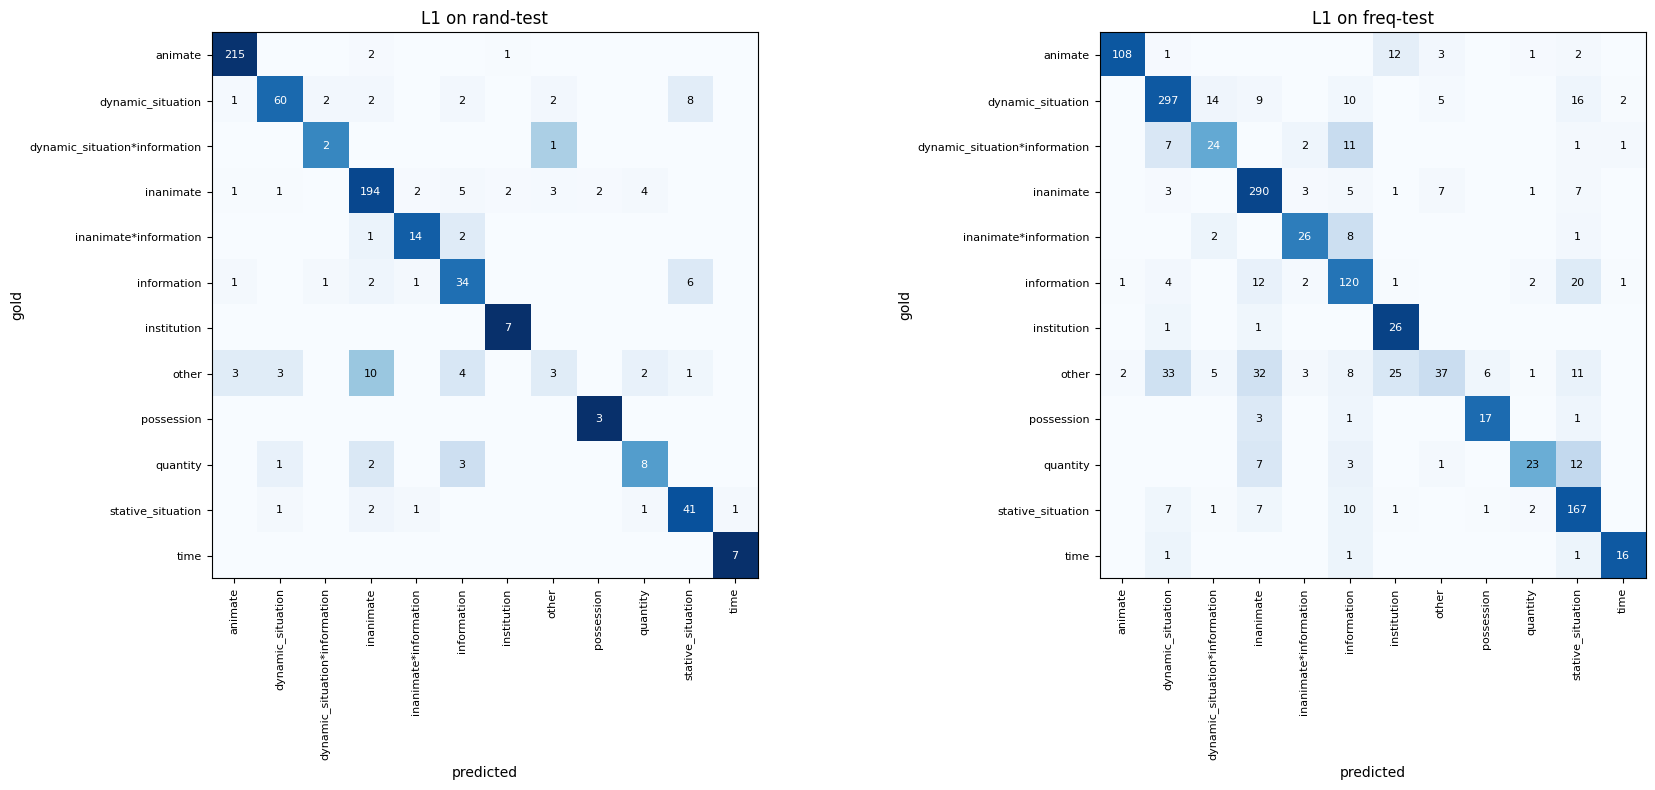

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, s in zip(axes, SPLITS):
    p = P[(MAIN, s)]
    cm = confusion_matrix(p["gold"], p["pred"], labels=labels)
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color="white" if norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(f"{MAIN} on {s}")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_L1.png"), dpi=150)
plt.show()

In [5]:
# Most frequent (gold -> predicted) error pairs
for s in SPLITS:
    err = P[(MAIN, s)].query("not correct")
    print(f"\n{s}: {len(err)} errors out of {len(P[(MAIN, s)])}")
    print(err.groupby(["gold", "pred"]).size().sort_values(ascending=False).head(10).to_string())


rand-test: 90 errors out of 678
gold               pred             
other              inanimate            10
dynamic_situation  stative_situation     8
information        stative_situation     6
inanimate          information           5
other              information           4
inanimate          quantity              4
quantity           information           3
other              dynamic_situation     3
                   animate               3
inanimate          other                 3

freq-test: 366 errors out of 1517
gold               pred                         
other              dynamic_situation                33
                   inanimate                        32
                   institution                      25
information        stative_situation                20
dynamic_situation  stative_situation                16
                   dynamic_situation*information    14
animate            institution                      12
information        inanimate   

## 3. The `other` class

In [6]:
for s in SPLITS:
    o = P[(MAIN, s)].query("gold == 'other'")
    print(f"{s}: {len(o)} gold 'other', recall = {o['correct'].mean():.3f}")
    print("  predicted as:", o["pred"].value_counts().to_dict())

# Examples of 'other' senses, with what the model predicted
P[(MAIN, "freq-test")].query("gold == 'other'").sample(15, random_state=SEED)[["lemma", "definition", "pred"]]

rand-test: 26 gold 'other', recall = 0.115
  predicted as: {'inanimate': 10, 'information': 4, 'dynamic_situation': 3, 'other': 3, 'animate': 3, 'quantity': 2, 'stative_situation': 1}
freq-test: 163 gold 'other', recall = 0.227
  predicted as: {'other': 37, 'dynamic_situation': 33, 'inanimate': 32, 'institution': 25, 'stative_situation': 11, 'information': 8, 'possession': 6, 'dynamic_situation*information': 5, 'inanimate*information': 3, 'animate': 2, 'quantity': 1}


,lemma,definition,pred
1181,société,"Lot, ensemble des chevaux concurrents d’une course hippique.",other
945,taille,"Bois, pierre ou marbre que l’on coupe avec art et selon certaines dimensions, pour les employer dans une construction.",inanimate
1169,hôte,Organisme qui héberge un parasite.,inanimate
526,écart,Action par laquelle deux parties d’une chose s’écartent plus ou moins l’une de l’autre.,dynamic_situation
697,première,Nom donné à tout événement qui ne s’était jusqu’alors jamais produit.,dynamic_situation
303,société,Assemblage d’hommes qui sont unis par la nature ou par des lois ; commerce que les hommes réunis ont naturellement l...,institution
1472,imprimerie,Établissement où l’on imprime.,institution
518,trace,"Marque ou empreinte laissée sur le sol par le passage d’une personne, d’un animal ou d’un objet.",inanimate
813,division,"Bureau d’un état-major qui traite les questions militaires d’une espèce particulière, telles que personnel, renseign...",institution
1368,réaction,Mouvement d’opinion qui agit dans un sens contraire au mouvement qui a précédé.,dynamic_situation*information


## 4. Composite labels
For senses whose gold label is composite (e.g. `inanimate*information`), how often is the prediction
exactly right, and how often is it one of the two components?

In [7]:
for s in SPLITS:
    c = P[(MAIN, s)][P[(MAIN, s)]["gold"].str.contains("*", regex=False)]
    partial = c.apply(lambda r: r["pred"] in r["gold"].split("*"), axis=1)
    print(f"{s}: {len(c)} composite senses | exact {c['correct'].mean():.3f} | "
          f"one component {partial.mean():.3f} | other label {1 - c['correct'].mean() - partial.mean():.3f}")

# Simple senses wrongly predicted as a composite label containing their gold label
for s in SPLITS:
    p = P[(MAIN, s)]
    over = p[~p["gold"].str.contains("*", regex=False) & p["pred"].str.contains("*", regex=False)]
    inside = over.apply(lambda r: r["gold"] in r["pred"].split("*"), axis=1)
    print(f"{s}: {len(over)} simple senses predicted as composite, {inside.sum()} of which contain the gold label")

rand-test: 20 composite senses | exact 0.800 | one component 0.150 | other label 0.050
freq-test: 83 composite senses | exact 0.602 | one component 0.313 | other label 0.084
rand-test: 7 simple senses predicted as composite, 6 of which contain the gold label
freq-test: 28 simple senses predicted as composite, 19 of which contain the gold label


## 5. Accuracy by instance properties
- **lemma frequency**: number of occurrences of the lemma in the FrSemCor corpus (column `nb_occ_lemma_frsemcor`);
- **definition length** in words;
- **context-dependent definitions**: definitions that refer to another sense or word
  (*cette action*, *Synonyme de*, *Ellipse de*, ...), which are hard to classify on their own.


accuracy of L1 by freq_bin
         rand-test      freq-test     
              mean size      mean size
freq_bin                              
0            0.904  492     0.794  243
1-5          0.765  162     0.768  941
6-50         0.810   21     0.710  317
>50          0.667    3     0.625   16

accuracy of L1 by len_bin
        rand-test      freq-test     
             mean size      mean size
len_bin                              
<=5         0.860  172     0.754  334
6-10        0.858  169     0.791  497
11-20       0.881  269     0.732  500
>20         0.853   68     0.753  186



accuracy of L1 by context_dependent
                  rand-test      freq-test      
                       mean size      mean  size
context_dependent                               
False                 0.865  637     0.761  1458
True                  0.902   41     0.695    59


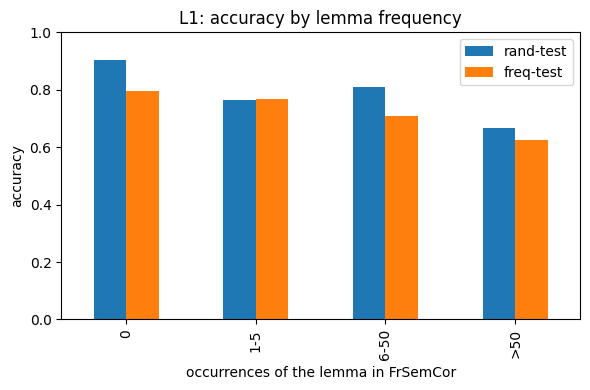

In [8]:
CONTEXT_PATTERN = re.compile(r"\b(cette|cet|ces)\b|^(Synonyme|Ellipse|Variante|Abréviation|Diminutif)\s+d",
                             flags=re.IGNORECASE)

def add_features(p):
    p = p.copy()
    p["freq_bin"] = pd.cut(p["lemma_freq"], [-1, 0, 5, 50, np.inf], labels=["0", "1-5", "6-50", ">50"])
    n_words = p["definition"].fillna("").str.split().str.len()
    p["len_bin"] = pd.cut(n_words, [-1, 5, 10, 20, np.inf], labels=["<=5", "6-10", "11-20", ">20"])
    p["context_dependent"] = p["definition"].fillna("").apply(lambda t: bool(CONTEXT_PATTERN.search(t)))
    return p

tables = {}
for feat in ["freq_bin", "len_bin", "context_dependent"]:
    t = pd.concat({s: add_features(P[(MAIN, s)]).groupby(feat, observed=True)["correct"].agg(["mean", "size"])
                   for s in SPLITS}, axis=1).round(3)
    tables[feat] = t
    print(f"\naccuracy of {MAIN} by {feat}"); print(t.to_string())

fig, ax = plt.subplots(figsize=(6, 4))
tables["freq_bin"].xs("mean", axis=1, level=1).plot.bar(ax=ax)
ax.set_xlabel("occurrences of the lemma in FrSemCor"); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1)
ax.set_title(f"{MAIN}: accuracy by lemma frequency")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "accuracy_by_lemma_freq.png"), dpi=150); plt.show()

## 6. Effect of the lemma (L1 vs L2)
- **McNemar test** (exact): compares the two models on the instances where exactly one of them is right.
- **Paired bootstrap** (2000 resamples of the test instances): 95% interval of the macro-F1 difference.
Both only account for the sampling of test instances, not for the run-to-run variance of training.

In [9]:
def mcnemar_p(only_a, only_b):
    """Exact two-sided McNemar test (binomial test on the discordant pairs)."""
    n, k = int(only_a + only_b), int(min(only_a, only_b))
    return min(1.0, 2 * sum(comb(n, i) for i in range(k + 1)) / 2 ** n)

def macro_f1(gold, pred):
    return f1_score(gold, pred, labels=sorted(set(gold)), average="macro", zero_division=0)

rng = np.random.default_rng(SEED)
for s in SPLITS:
    a, b = P[(MAIN, s)], P[(NO_LEMMA, s)]
    assert (a["sense_id"].values == b["sense_id"].values).all()
    g, pa, pb = a["gold"].values, a["pred"].values, b["pred"].values
    only_a, only_b = int((a["correct"] & ~b["correct"]).sum()), int((~a["correct"] & b["correct"]).sum())
    diffs = []
    for _ in range(2000):
        i = rng.integers(0, len(g), len(g))
        diffs.append(macro_f1(g[i], pa[i]) - macro_f1(g[i], pb[i]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f"{s}: acc {a['correct'].mean():.3f} vs {b['correct'].mean():.3f} | "
          f"only {MAIN} right: {only_a}, only {NO_LEMMA} right: {only_b}, McNemar p = {mcnemar_p(only_a, only_b):.2g} | "
          f"macro-F1 diff {macro_f1(g, pa) - macro_f1(g, pb):+.3f}, 95% CI [{lo:+.3f}, {hi:+.3f}]")

rand-test: acc 0.867 vs 0.854 | only L1 right: 27, only L2 right: 18, McNemar p = 0.23 | macro-F1 diff +0.013, 95% CI [-0.024, +0.050]


freq-test: acc 0.759 vs 0.721 | only L1 right: 119, only L2 right: 61, McNemar p = 1.8e-05 | macro-F1 diff +0.050, 95% CI [+0.025, +0.076]


In [10]:
# Which classes gain from the lemma? (recall with lemma minus recall without, freq-test)
s = "freq-test"
a, b = P[(MAIN, s)], P[(NO_LEMMA, s)]
gain = pd.DataFrame({"support": a.groupby("gold").size(),
                     "recall_L1": a.groupby("gold")["correct"].mean(),
                     "recall_L2": b.groupby("gold")["correct"].mean()})
gain["gain"] = gain["recall_L1"] - gain["recall_L2"]
gain.round(3).sort_values("gain", ascending=False)

,support,recall_L1,recall_L2,gain
gold,,,,
inanimate*information,37,0.703,0.514,0.189
institution,28,0.929,0.750,0.179
dynamic_situation*information,46,0.522,0.413,0.109
information,163,0.736,0.650,0.086
other,163,0.227,0.172,0.055
dynamic_situation,353,0.841,0.799,0.042
stative_situation,196,0.852,0.816,0.036
inanimate,317,0.915,0.905,0.009
possession,22,0.773,0.773,0.000


In [11]:
# Examples where only the model with the lemma is right
only_l1 = a[a["correct"].values & ~b["correct"].values].copy()
only_l1["pred_without_lemma"] = b.loc[only_l1.index, "pred"]
only_l1.sample(15, random_state=SEED)[["lemma", "definition", "gold", "pred_without_lemma"]]

,lemma,definition,gold,pred_without_lemma
739,copie,Reproduction d’un ouvrage d’art.,inanimate*information,dynamic_situation
1222,extension,Action de ce qui s’étend ; se dit surtout des membres.,dynamic_situation,other
28,milieu,"Pègre, l’ensemble des délinquants et des criminels.",animate,institution
663,zone,"Exprime un désordre, le bazar, le bordel.",stative_situation,dynamic_situation
298,inscription,"Action d’inscrire, résultat de cette action.",other,dynamic_situation
1486,majorité,Résidence de l’état-major dans un port.,other,institution
925,entrée,Donnée récupérée ou injectée dans un programme ou une fonction.,information,dynamic_situation
131,objectif,Tout ce qui est en dehors du sujet pensant et observant.,information,stative_situation
1229,extension,"Action d’étendre la signification d’un mot, tient le milieu entre le sens propre et le sens figuré.",dynamic_situation,dynamic_situation*information
1007,création,"Univers, monde, ensemble des choses créées.",other,inanimate


## 7. ICL (E7) vs LoRA (L1)
Overlap of the errors of the two methods on the same senses, and recall per class.

In [12]:
for s in SPLITS:
    m = P[(ICL_RUN, s)][["sense_id", "gold", "pred", "correct"]].merge(
        P[(MAIN, s)][["sense_id", "pred", "correct"]], on="sense_id", suffixes=("_icl", "_lora"))
    ci, cl = m["correct_icl"], m["correct_lora"]
    print(f"{s}: n={len(m)} | ICL acc {ci.mean():.3f} | LoRA acc {cl.mean():.3f} | "
          f"only ICL right {int((ci & ~cl).sum())}, only LoRA right {int((~ci & cl).sum())}, "
          f"McNemar p = {mcnemar_p((ci & ~cl).sum(), (~ci & cl).sum()):.1e}")
    print(f"  share of LoRA errors that are also ICL errors: {(~ci & ~cl).sum() / (~cl).sum():.3f}")
    print("  ICL predicted label distribution:", m["pred_icl"].value_counts(normalize=True).round(3).head(6).to_dict())

# Recall per class of both methods
rec = pd.concat({(run, s): P[(run, s)].groupby("gold")["correct"].mean()
                 for run in [ICL_RUN, MAIN] for s in SPLITS}, axis=1).round(3)
rec

rand-test: n=678 | ICL acc 0.519 | LoRA acc 0.867 | only ICL right 20, only LoRA right 256, McNemar p = 2.4e-53
  share of LoRA errors that are also ICL errors: 0.778
  ICL predicted label distribution: {'inanimate': 0.403, 'animate': 0.178, 'other': 0.124, 'dynamic_situation': 0.075, 'inanimate*information': 0.055, 'quantity': 0.029}
freq-test: n=1517 | ICL acc 0.328 | LoRA acc 0.759 | only ICL right 58, only LoRA right 711, McNemar p = 8.0e-144
  share of LoRA errors that are also ICL errors: 0.842
  ICL predicted label distribution: {'inanimate': 0.249, 'other': 0.206, 'dynamic_situation': 0.174, 'possession': 0.071, 'institution': 0.065, 'stative_situation': 0.048}


E7                  L1          
                              rand-test freq-test rand-test freq-test
gold                                                                 
animate                           0.550     0.063     0.986     0.850
dynamic_situation                 0.351     0.462     0.779     0.841
dynamic_situation*information     0.000     0.087     0.667     0.522
inanimate                         0.734     0.562     0.907     0.915
inanimate*information             0.588     0.270     0.824     0.703
information                       0.111     0.123     0.756     0.736
institution                       0.429     0.714     1.000     0.929
other                             0.154     0.123     0.115     0.227
possession                        0.333     0.409     1.000     0.773
quantity                          0.643     0.500     0.571     0.500
stative_situation                 0.234     0.168     0.872     0.852
time                              0.714     0.526     1.000     0.842

## 8. Export of the errors for manual reading

In [13]:
for s in SPLITS:
    err = add_features(P[(MAIN, s)]).query("not correct")
    err = err.assign(pred_without_lemma=P[(NO_LEMMA, s)].loc[err.index, "pred"].values)
    cols = ["sense_id", "lemma", "definition", "gold", "pred", "pred_without_lemma",
            "supersense", "lemma_freq", "context_dependent"]
    err[cols].sort_values(["gold", "pred"]).to_csv(os.path.join(FIG_DIR, f"errors_{MAIN}_{s}.csv"), index=False)
print(sorted(os.listdir(FIG_DIR)))

['accuracy_by_lemma_freq.png', 'confusion_L1.png', 'errors_L1_freq-test.csv', 'errors_L1_rand-test.csv', 'per_class_L1.csv']
